<a href="https://colab.research.google.com/github/Pavlenko-Kateryna/da_course/blob/main/HW_16_2_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D0%BA%D1%80%D0%B5%D0%B4%D0%B8%D1%82%D0%BD%D0%BE%D0%B3%D0%BE_%D1%80%D0%B8%D0%B7%D0%B8%D0%BA%D1%83.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Прогнозування кредитного ризику

## Мета завдання
Застосувати знання з лекції для побудови моделі логістичної регресії, що прогнозує ймовірність дефолту за кредитом, іншими словами, що людина не поверне кредит. Ви пройдете весь цикл: від дослідницького аналізу до оцінки якості класифікаційної моделі.

## Опис датасету
**Credit Risk Dataset** містить інформацію про 32,000+ позичальників з такими параметрами:
- **person_age**: Вік позичальника
- **person_income**: Річний дохід
- **person_home_ownership**: Тип володіння житлом
- **person_emp_length**: Стаж роботи (в роках)
- **loan_intent**: Мета кредиту
- **loan_grade**: Кредитний рейтинг (A - кращий, F - гірший)
- **loan_amnt**: Сума кредиту
- **loan_int_rate**: Процентна ставка
- **loan_status**: Статус кредиту (0 = сплачено, 1 = дефолт) - **цільова змінна**
- **loan_percent_income**: Відношення кредиту до доходу
- **cb_person_default_on_file**: Історія дефолтів (Y/N)
- **cb_person_cred_hist_length**: Довжина кредитної історії

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `credit_risk_dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (кількість записів, типи колонок)
5. Перевірте розподіл цільової змінної (відсотк даних для кожного класу)

Дайте висновок, це задача збалансованої чи незбалансованої класифікації.


In [30]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/credit_risk_dataset.csv")
df.shape

(32581, 12)

In [31]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [33]:
loan_perc = df['loan_status'].value_counts(normalize=True)* 100
loan_perc

,proportion
loan_status,
0,78.183604
1,21.816396


Маємо задачу незбалансованої вибірки, адже 0 переважає 1 більше ніж у 3 рази (майже 4).


---

## Завдання 2: Дослідницький аналіз даних (EDA) (4 бали)

**Що потрібно зробити:**
1. Обчисліть відсоток пропущених значень в колонках. За наявності пропущених значень - заповніть їх медіаною для числових колонок і найбільш частим значеннмя для категоріальних.
2. Проаналізуйте розподіл числових змінних.
3. Знайдіть та обробіть викиди в колонці person_income з допомогою [Interquartile range](https://uk.wikipedia.org/wiki/%D0%9C%D1%96%D0%B6%D0%BA%D0%B2%D0%B0%D1%80%D1%82%D0%B8%D0%BB%D1%8C%D0%BD%D0%B8%D0%B9_%D1%80%D0%BE%D0%B7%D0%BC%D0%B0%D1%85).
4. Проаналізуйте категоріальні змінні відносно цільової та частоту зустрічання різних значень в них.
5. Візуалізуйте взаємозв'язок ознак з цільовою змінною.


In [34]:
missing_counts = df.isnull().sum()
missing_perc = (missing_counts / len(df) * 100).round(2)
missing_perc

,0
person_age,0.00
person_income,0.00
person_home_ownership,0.00
person_emp_length,2.75
loan_intent,0.00
loan_grade,0.00
loan_amnt,0.00
loan_int_rate,9.56
loan_status,0.00
loan_percent_income,0.00


Маємо пропуски у person_emp_length (стаж роботи) та loan_int_rate (процентна ставка). Обидві колонки - числові, то заповнимо пропуски медіаною.

In [35]:
df['person_emp_length'] = df['person_emp_length'].fillna(df['person_emp_length'].median())
df['loan_int_rate'] = df['loan_int_rate'].fillna(df['loan_int_rate'].median())

In [36]:
missing_counts = df.isnull().sum()
missing_perc = (missing_counts / len(df) * 100).round(2)
missing_perc

,0
person_age,0.0
person_income,0.0
person_home_ownership,0.0
person_emp_length,0.0
loan_intent,0.0
loan_grade,0.0
loan_amnt,0.0
loan_int_rate,0.0
loan_status,0.0
loan_percent_income,0.0


In [37]:
df.dtypes

,0
person_age,int64
person_income,int64
person_home_ownership,object
person_emp_length,float64
loan_intent,object
loan_grade,object
loan_amnt,int64
loan_int_rate,float64
loan_status,int64
loan_percent_income,float64


In [38]:
num_cats = df.select_dtypes("number")
num_cats

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
0,22,59000,123.0,35000,16.02,1,0.59,3
1,21,9600,5.0,1000,11.14,0,0.10,2
2,25,9600,1.0,5500,12.87,1,0.57,3
3,23,65500,4.0,35000,15.23,1,0.53,2
4,24,54400,8.0,35000,14.27,1,0.55,4
...,...,...,...,...,...,...,...,...
32576,57,53000,1.0,5800,13.16,0,0.11,30
32577,54,120000,4.0,17625,7.49,0,0.15,19
32578,65,76000,3.0,35000,10.99,1,0.46,28
32579,56,150000,5.0,15000,11.48,0,0.10,26


In [39]:
num_cats.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.767994,9589.371106,11.009620,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.087372,6322.086646,3.081611,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,8.490000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.110000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


Як можемо побачити з процентилів, у більшості розподіл наближений до нормального, але перевіримо це за допомогою boxplot і заодно побачимо викиди.

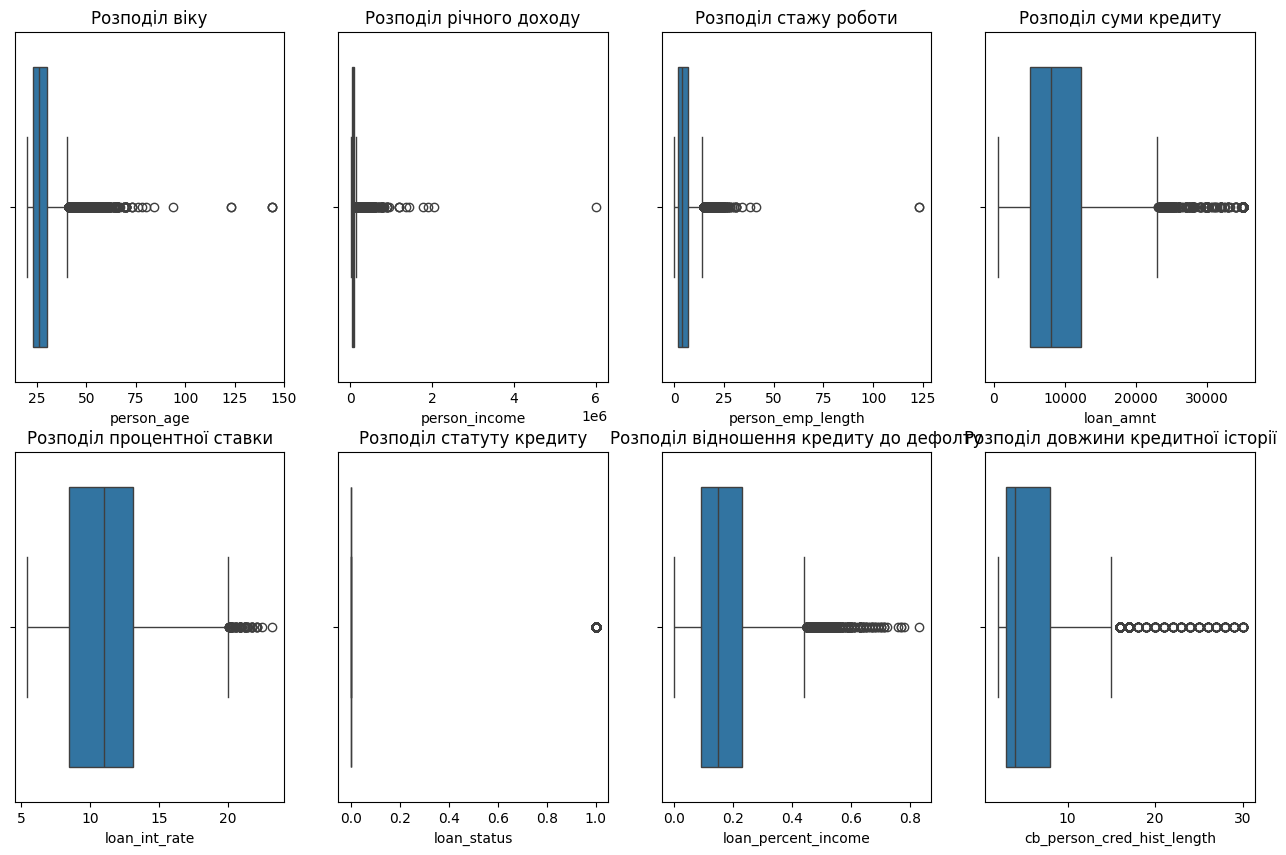

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 10))

sns.boxplot(data=df,x='person_age', ax=axes[0,0])
axes[0, 0].set_title("Розподіл віку")

sns.boxplot(data=df,x='person_income', ax=axes[0,1])
axes[0, 1].set_title("Розподіл річного доходу")

sns.boxplot(data=df,x='person_emp_length', ax=axes[0,2])
axes[0, 2].set_title("Розподіл стажу роботи")

sns.boxplot(data=df,x='loan_amnt', ax=axes[0,3])
axes[0, 3].set_title("Розподіл суми кредиту")

sns.boxplot(data=df,x='loan_int_rate', ax=axes[1,0])
axes[1, 0].set_title("Розподіл процентної ставки")

sns.boxplot(data=df,x='loan_status', ax=axes[1,1])
axes[1, 1].set_title("Розподіл статуту кредиту")

sns.boxplot(data=df,x='loan_percent_income', ax=axes[1,2])
axes[1, 2].set_title("Розподіл відношення кредиту до дефолту")

sns.boxplot(data=df,x='cb_person_cred_hist_length', ax=axes[1,3])
axes[1, 3].set_title("Розподіл довжини кредитної історії")

plt.show()

Як бачимо маємо декільки викидів у всіх колонках, тому будемо очищати їх. За умовою треба очистити person_income (річний дохід).

In [42]:
Q1 = (df['person_income'].sort_values(ascending=True)).quantile(0.25)
Q3 = (df['person_income'].sort_values(ascending=True)).quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Нижня межа:", lower_bound)
print("Верхня межа:", upper_bound)

Нижня межа: -22550.0
Верхня межа: 140250.0


In [43]:
outliers = df[(df['person_income'] < lower_bound ) | (df['person_income'] > upper_bound)]
print(f"Outliers: {len(outliers)}")

Outliers: 1484


In [44]:
df = df[(df['person_income'] >= lower_bound ) & (df['person_income'] <= upper_bound)]

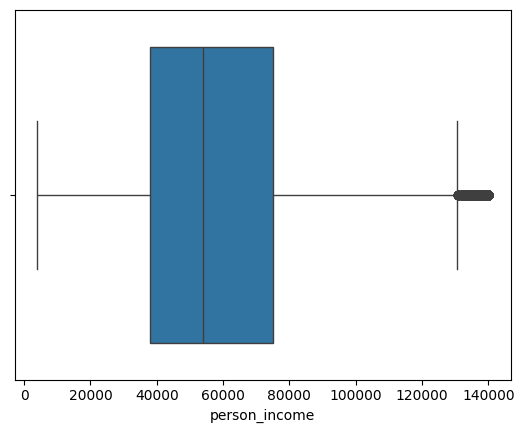

In [45]:
sns.boxplot(data=df,x='person_income')
plt.show()

In [46]:
cat_cols = df.select_dtypes("object")
cat_cols

,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
0,RENT,PERSONAL,D,Y
1,OWN,EDUCATION,B,N
2,MORTGAGE,MEDICAL,C,N
3,RENT,MEDICAL,C,N
4,RENT,MEDICAL,C,Y
...,...,...,...,...
32575,RENT,EDUCATION,B,N
32576,MORTGAGE,PERSONAL,C,N
32577,MORTGAGE,PERSONAL,A,N
32578,RENT,HOMEIMPROVEMENT,B,N


частота зустрічання різних значень

In [51]:
for col in cat_cols:
  cat_values = df[col].value_counts()
  cat_perc = df[col].value_counts(normalize=True) * 100
  summary = pd.DataFrame({'Кількість': cat_values, 'Відсоток (%)': cat_perc.round(2)})
  print(summary)
  print("/n")

                       Кількість  Відсоток (%)
person_home_ownership                         
RENT                       16102         51.78
MORTGAGE                   12426         39.96
OWN                         2469          7.94
OTHER                        100          0.32
/n
                   Кількість  Відсоток (%)
loan_intent                               
EDUCATION               6201         19.94
MEDICAL                 5846         18.80
VENTURE                 5445         17.51
PERSONAL                5260         16.91
DEBTCONSOLIDATION       4955         15.93
HOMEIMPROVEMENT         3390         10.90
/n
            Кількість  Відсоток (%)
loan_grade                         
A               10343         33.26
B                9924         31.91
C                6191         19.91
D                3459         11.12
E                 899          2.89
F                 221          0.71
G                  60          0.19
/n
                           Кількість  Від

категоріальні змінні відносно цільової

In [53]:
target = 'loan_status'
for col in cat_cols:
  cat_values = df.groupby(col)[target].value_counts()
  cat_perc = df.groupby(col)[target].value_counts(normalize=True) * 100
  summary = pd.DataFrame({'Кількість': cat_values, 'Відсоток (%)': cat_perc.round(2)})
  print(summary)
  print("/n")

                                   Кількість  Відсоток (%)
person_home_ownership loan_status                         
MORTGAGE              0                10831         87.16
                      1                 1595         12.84
OTHER                 0                   68         68.00
                      1                   32         32.00
OWN                   0                 2277         92.22
                      1                  192          7.78
RENT                  0                10958         68.05
                      1                 5144         31.95
/n
                               Кількість  Відсоток (%)
loan_intent       loan_status                         
DEBTCONSOLIDATION 0                 3514         70.92
                  1                 1441         29.08
EDUCATION         0                 5109         82.39
                  1                 1092         17.61
HOMEIMPROVEMENT   0                 2468         72.80
                  1   

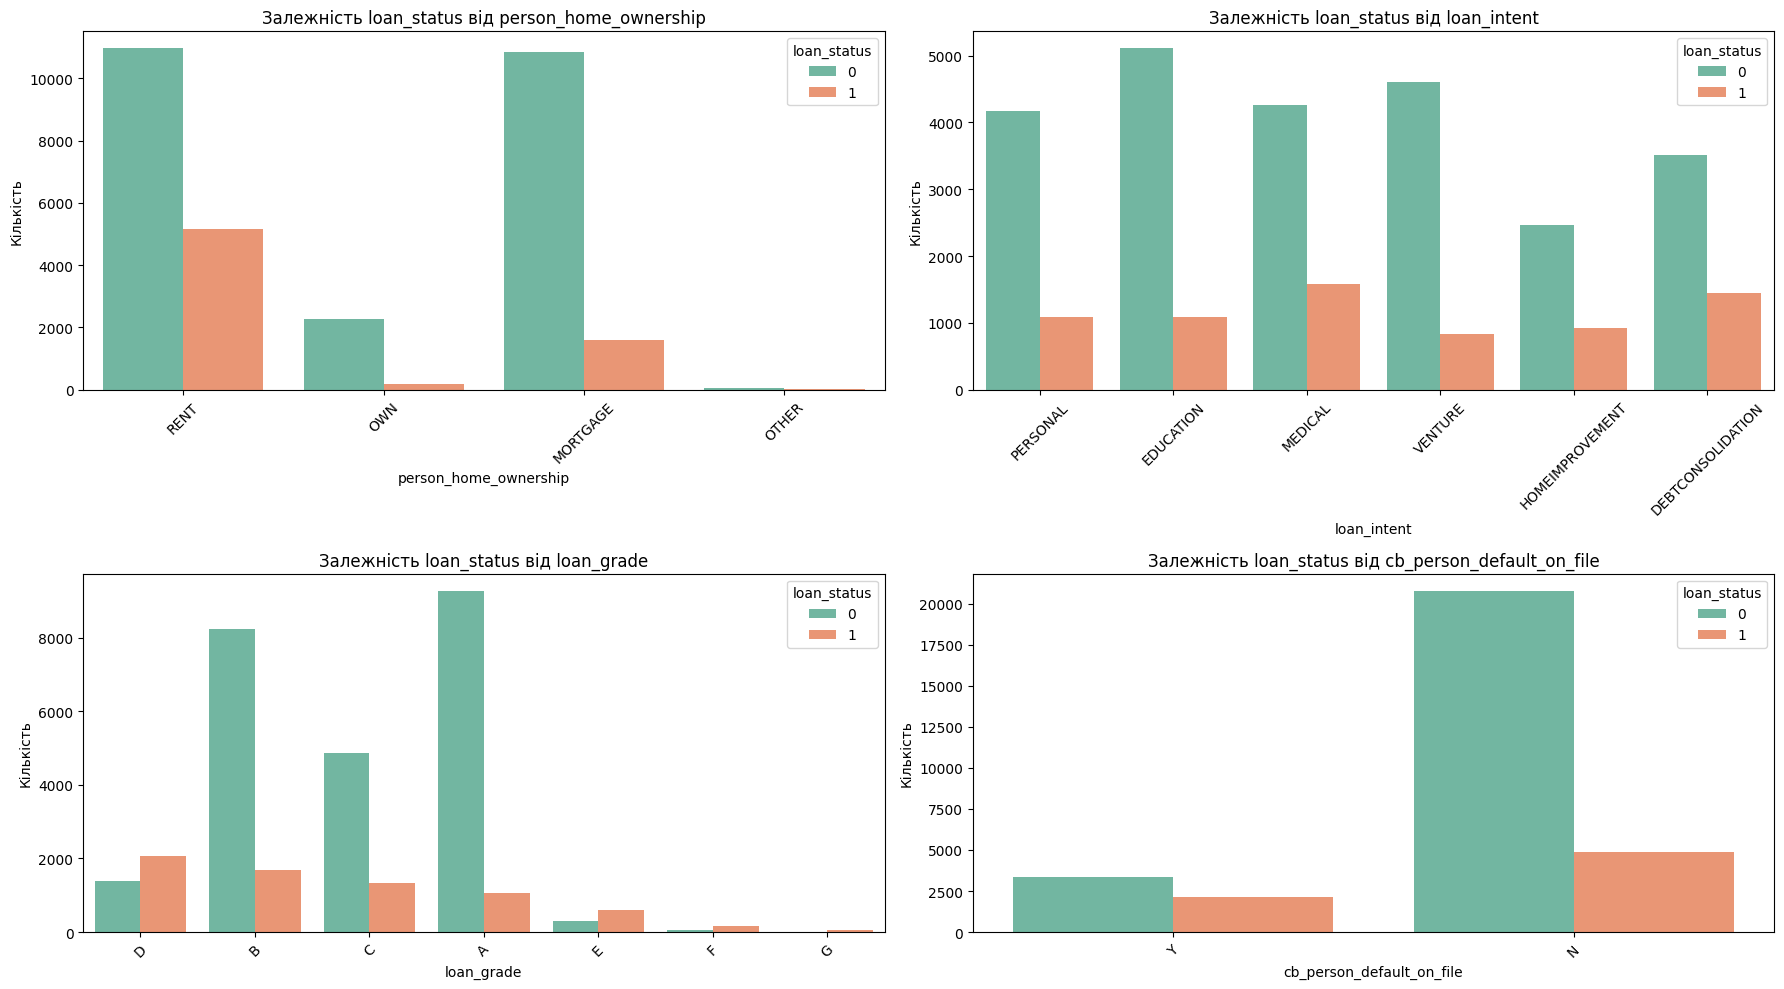

In [59]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18, 10))

axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue=target, palette='Set2', ax=axes[i])

    axes[i].set_title(f'Залежність {target} від {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Кількість')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend(title=target)

plt.tight_layout()
plt.show()


---

## Завдання 3: Аналіз кореляцій та Feature Engineering (3 бали)

**Що потрібно зробити:**
1. Побудуйте матрицю кореляцій для числових змінних.
2. Закодуйте категоріальні змінні.
3. Виберіть фінальний набір ознак, можна лишити всі, якщо ви вважаєте, що це - доцільно.



In [60]:
correlation = num_cats.corr()
correlation

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
person_age,1.000000,0.173202,0.161454,0.050787,0.011853,-0.021629,-0.042411,0.859133
person_income,0.173202,1.000000,0.135164,0.266820,0.000746,-0.144449,-0.254471,0.117987
person_emp_length,0.161454,0.135164,1.000000,0.113851,-0.051262,-0.082182,-0.054134,0.143069
loan_amnt,0.050787,0.266820,0.113851,1.000000,0.139483,0.105376,0.572612,0.041967
loan_int_rate,0.011853,0.000746,-0.051262,0.139483,1.000000,0.319360,0.114514,0.015762
loan_status,-0.021629,-0.144449,-0.082182,0.105376,0.319360,1.000000,0.379366,-0.015529
loan_percent_income,-0.042411,-0.254471,-0.054134,0.572612,0.114514,0.379366,1.000000,-0.031690
cb_person_cred_hist_length,0.859133,0.117987,0.143069,0.041967,0.015762,-0.015529,-0.031690,1.000000


In [63]:
for col in cat_cols.columns:
    print(cat_cols[col].value_counts())

person_home_ownership
RENT        16102
MORTGAGE    12426
OWN          2469
OTHER         100
Name: count, dtype: int64
loan_intent
EDUCATION            6201
MEDICAL              5846
VENTURE              5445
PERSONAL             5260
DEBTCONSOLIDATION    4955
HOMEIMPROVEMENT      3390
Name: count, dtype: int64
loan_grade
A    10343
B     9924
C     6191
D     3459
E      899
F      221
G       60
Name: count, dtype: int64
cb_person_default_on_file
N    25626
Y     5471
Name: count, dtype: int64


In [75]:
encoded_df = pd.get_dummies(df,columns=['person_home_ownership', 'loan_intent', 'loan_grade'])
encoded_df['cb_person_default_on_file'] = encoded_df['cb_person_default_on_file'].map({'N': 0,'Y': 1})
encoded_df

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership_MORTGAGE,...,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_A,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G
0,22,59000,123.0,35000,16.02,1,0.59,1,3,False,...,False,True,False,False,False,False,True,False,False,False
1,21,9600,5.0,1000,11.14,0,0.10,0,2,False,...,False,False,False,False,True,False,False,False,False,False
2,25,9600,1.0,5500,12.87,1,0.57,0,3,True,...,True,False,False,False,False,True,False,False,False,False
3,23,65500,4.0,35000,15.23,1,0.53,0,2,False,...,True,False,False,False,False,True,False,False,False,False
4,24,54400,8.0,35000,14.27,1,0.55,1,4,False,...,True,False,False,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32575,52,64500,0.0,5000,11.26,0,0.08,0,20,False,...,False,False,False,False,True,False,False,False,False,False
32576,57,53000,1.0,5800,13.16,0,0.11,0,30,True,...,False,True,False,False,False,True,False,False,False,False
32577,54,120000,4.0,17625,7.49,0,0.15,0,19,True,...,False,True,False,True,False,False,False,False,False,False
32578,65,76000,3.0,35000,10.99,1,0.46,0,28,False,...,False,False,False,False,True,False,False,False,False,False


Для зручності аналізу, обираю залишити всі ознаки


---

## Завдання 4: Підготовка даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на X та y
2. Поділіть на навчальну та тестову вибірки
3. Застосуйте масштабування
4. Навчіть модель логістичної регресії
5. Зробіть прогнози на тренувальній та тестовій вибірках.



In [76]:
X = encoded_df.drop(columns=['loan_status'])
y = encoded_df['loan_status']

In [77]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)

print(f"Train: {X_train.shape[0]} клієнтів")
print(f"Test: {X_test.shape[0]} клієнтів")
print(f"Відтік в train: {y_train.mean():.1%}")
print(f"Відтік в test: {y_test.mean():.1%}")

Train: 24877 клієнтів
Test: 6220 клієнтів
Відтік в train: 22.4%
Відтік в test: 22.4%


In [78]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [79]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42, max_iter=1000)

model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [81]:
y_pred = model.predict(X_test_scaled)

y_pred_proba = model.predict_proba(X_test_scaled)

predictions = pd.DataFrame({
    'Реальний статус кредиту': y_test.values[:5],
    'Прогноз': y_pred[:5],
    'Ймовірність сплатити': y_pred_proba[:5, 0].round(3),
    'Ймовірність дефолту': y_pred_proba[:5, 1].round(3)
})
print(predictions)

   Реальний статус кредиту  Прогноз  Ймовірність сплатити  Ймовірність дефолту
0                        0        0                 0.969                0.031
1                        0        0                 0.986                0.014
2                        0        0                 0.965                0.035
3                        0        0                 0.965                0.035
4                        0        1                 0.165                0.835



---

## Завдання 5: Оцінка якості моделі (4 бали)

**Що потрібно зробити:**
1. Побудуйте confusion matrix.
2. Обчисліть основні метрики (accuracy, precision, recall, f1).
3. Побудуйте ROC-криву та обчисліть AUC
4. Проаналізуйте важливість ознак.
5. Зробіть висновки про якість моделі та які ознаки найбільше впливають на прогноз.


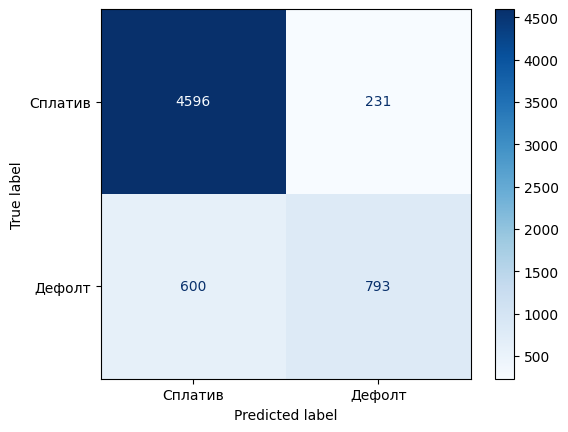

In [84]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,recall_score, f1_score

cm = confusion_matrix(y_test, y_pred)

displ = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Сплатив', 'Дефолт'])
displ.plot(cmap='Blues')
plt.show()

In [85]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy (Точність):    {accuracy:.3f}")
print(f"Precision (Влучність):  {precision:.3f}")
print(f"Recall (Повнота):       {recall:.3f}")
print(f"F1-score:               {f1:.3f}")

Accuracy (Точність):    0.866
Precision (Влучність):  0.774
Recall (Повнота):       0.569
F1-score:               0.656


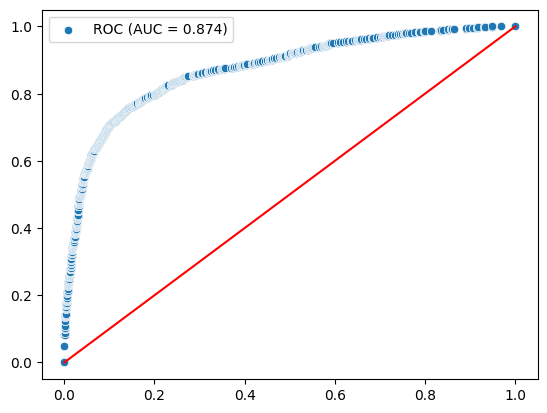

In [93]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba[:, 1])
auc = roc_auc_score(y_test, y_pred_proba[:, 1])

sns.scatterplot(x=fpr,y=tpr,label=f'ROC (AUC = {auc:.3f})')
sns.lineplot(x=[0, 1], y=[0, 1],color='red')
plt.show()

Маємо хорошу модель, бо AUC у межає 0.8-0.9

In [95]:
import numpy as np
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model.coef_[0],
    'abs_coefficient': np.abs(model.coef_[0])
}).sort_values('abs_coefficient', ascending=False)

feature_importance

,feature,coefficient,abs_coefficient
5,loan_percent_income,1.319718,1.319718
21,loan_grade_D,0.599974,0.599974
3,loan_amnt,-0.547966,0.547966
10,person_home_ownership_OWN,-0.495489,0.495489
22,loan_grade_E,0.362489,0.362489
11,person_home_ownership_RENT,0.335079,0.335079
18,loan_grade_A,-0.317706,0.317706
24,loan_grade_G,0.278026,0.278026
17,loan_intent_VENTURE,-0.228235,0.228235
23,loan_grade_F,0.212419,0.212419


Модель має хороший f1 score = 0.66, це означає що вона на 66% прогнозує правильно, але з матриці плутанини можемо побачити, що вона робить багато помилок на хибнопозитивному результаті (клієнт має дефолт, модель каже що сплатив).

З ознак найбільше впливає відношення кредиту до доходу (чи хможе клієнт оплачувати його), кредитний рейтинг (гірший рейтинг має більше значення) і сума кредиту. Тобто модель враховує релевантні ознаки


---

## Завдання 6: Оптимізація порогу та бізнес-аналіз (2 бали)

**Що потрібно зробити:**
1. Проаналізуйте метрики precision, recall, F1 при різних порогах класифікації (мінімум - 5 різних порогів). Візуалізуйте як змінюються метрики якості при зміні порогу.
2. Оберіть оптимальний поріг для бізнес-задачі - можна обрати виходячи з попереднього пункту, або додати своїх роздумів і обрати інший.



In [96]:
import plotly.express as px

thresholds = np.arange(0.1, 0.91, 0.05)
metrics_by_threshold = []

for threshold in thresholds:
    y_pred_custom = (y_pred_proba[:, 1] >= threshold).astype(int)

    metrics_by_threshold.append({
        'threshold': threshold,
        'precision': precision_score(y_test, y_pred_custom),
        'recall': recall_score(y_test, y_pred_custom),
        'f1': f1_score(y_test, y_pred_custom)
    })

metrics_df = pd.DataFrame(metrics_by_threshold)

# Візуалізація
fig = px.line(
    metrics_df.melt(id_vars='threshold'),
    x='threshold',
    y='value',
    color='variable',
    title='Метрики при різних порогах рішення',
    labels={'value': 'Значення метрики', 'threshold': 'Поріг'},
)
fig.show()

Оптимальний поріг точності - 0.35


---

## Завдання 7 (Опціональне): Покращення моделі та висновки (2 бали)

**Що потрібно зробити:**

На цих же даних навчіть DecisionTreeClassifier та RandomForestClassifier. Яка з трьох моделей дає найкращий результат на тестовому наборі?

Поріг класифікації можна для порівняння якостей моделей використовувати стандартний 0.5, або той, що ви виявили, як оптимальний на попередньому кроці.
